In [1]:
from pathlib import Path

FIGURES_DIR = Path("../figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

def save_and_show(stem):
    """Save each open figure as PNG and vector PDF, then display it."""
    for index, number in enumerate(plt.get_fignums(), start=1):
        fig = plt.figure(number)
        suffix = f"_{index}" if len(plt.get_fignums()) > 1 else ""
        fig.savefig(FIGURES_DIR / f"{stem}{suffix}.png", dpi=180, bbox_inches="tight")
        fig.savefig(FIGURES_DIR / f"{stem}{suffix}.pdf", bbox_inches="tight")
    plt.show()
    plt.close("all")


In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Reproducibility
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

In [3]:
# Core experiment settings
N_TRAIN = 150
N_TEST = 1000
D_MAX = 400
NOISE_STD = 0.5

# Model dimensions to test
D_VALUES = np.array([
    10, 20, 40, 60, 80, 100, 120, 130, 140,
    145, 148, 149, 150, 151, 152, 155, 160,
    170, 180, 200, 250, 300, 350, 400
])

print(f"Training samples: {N_TRAIN}")
print(f"Test samples: {N_TEST}")
print(f"Interpolation threshold: d = {N_TRAIN}")

Training samples: 150
Test samples: 1000
Interpolation threshold: d = 150


## Synthetic data-generating process

We generate independent training and test features from a standard Gaussian distribution and use noisy linear labels, $y = X\beta + \varepsilon$, with independent Gaussian noise of standard deviation `NOISE_STD = 0.5`.

The coefficient magnitudes decay with feature index: $\beta_j \propto s_j\exp(-0.02j)$, where $j=0,\ldots,D_{\max}-1$ and each $s_j$ is a random sign. We normalize the coefficient vector to Euclidean norm one, giving population signal variance one under the Gaussian feature distribution.

Earlier features therefore carry more signal. Adding the first `d` features progressively captures the signal and reduces omitted-variable error. Beyond that benefit, increasing dimension also affects estimation variance and, in the overparameterized regime, the minimum-norm solution's bias. This ordering is a deliberate synthetic design choice; it does not imply that real-world features naturally arrive in this order, or guarantee a particular test-error curve.

Within each run, the full dataset and labels stay fixed as `d` varies: models use nested prefixes of the same feature matrices. The main run resets its generator to `RANDOM_SEED`; repeated runs use their explicitly supplied seeds and the same coefficient construction.


In [4]:
# Generate a reproducible synthetic regression dataset

data_rng = np.random.default_rng(RANDOM_SEED)

# Feature matrices
X_train_full = data_rng.normal(
    loc=0.0,
    scale=1.0,
    size=(N_TRAIN, D_MAX)
)

X_test_full = data_rng.normal(
    loc=0.0,
    scale=1.0,
    size=(N_TEST, D_MAX)
)

# True coefficients:
# earlier features carry more signal than later ones
feature_index = np.arange(D_MAX)

signs = data_rng.choice([-1.0, 1.0], size=D_MAX)

beta_true = signs * np.exp(-0.02 * feature_index)

# Normalize total signal strength
beta_true = beta_true / np.linalg.norm(beta_true)

# Add Gaussian noise
train_noise = data_rng.normal(
    loc=0.0,
    scale=NOISE_STD,
    size=N_TRAIN
)

test_noise = data_rng.normal(
    loc=0.0,
    scale=NOISE_STD,
    size=N_TEST
)

# Labels: y = X beta + noise
y_train = X_train_full @ beta_true + train_noise
y_test = X_test_full @ beta_true + test_noise

print("X_train shape:", X_train_full.shape)
print("X_test shape:", X_test_full.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)
print("beta norm:", np.linalg.norm(beta_true))

X_train shape: (150, 400)
X_test shape: (1000, 400)
y_train shape: (150,)
y_test shape: (1000,)
beta norm: 0.9999999999999999


In [5]:
def fit_min_norm_least_squares(X, y, tol=1e-10):
    """
    Fit linear regression using the minimum-norm least squares solution.

    Works both when:
    - d < n  : ordinary least squares
    - d >= n : minimum-norm interpolating solution
    """

    # Singular Value Decomposition
    U, singular_values, Vt = np.linalg.svd(
        X,
        full_matrices=False
    )

    # Avoid dividing by singular values that are numerically zero
    cutoff = tol * singular_values[0]

    inverse_singular_values = np.where(
        singular_values > cutoff,
        1.0 / singular_values,
        0.0
    )

    # Moore-Penrose solution
    w = Vt.T @ (
        inverse_singular_values * (U.T @ y)
    )

    return w


def mean_squared_error(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

In [6]:
# Quick test in the underparameterized regime

d = 40

X_train = X_train_full[:, :d]
X_test = X_test_full[:, :d]

w_hat = fit_min_norm_least_squares(
    X_train,
    y_train
)

train_predictions = X_train @ w_hat
test_predictions = X_test @ w_hat

train_mse = mean_squared_error(
    y_train,
    train_predictions
)

test_mse = mean_squared_error(
    y_test,
    test_predictions
)

print("d =", d)
print("w shape:", w_hat.shape)
print("Train MSE:", train_mse)
print("Test MSE:", test_mse)

d = 40
w shape: (40,)
Train MSE: 0.3688858806787832
Test MSE: 0.5893246800404917


In [8]:
train_errors = []
test_errors = []

for d in D_VALUES:

    # Use only the first d features
    X_train = X_train_full[:, :d]
    X_test = X_test_full[:, :d]

    # Fit minimum-norm least squares
    w_hat = fit_min_norm_least_squares(
        X_train,
        y_train
    )

    # Predictions
    train_predictions = X_train @ w_hat
    test_predictions = X_test @ w_hat

    # Errors
    train_mse = mean_squared_error(
        y_train,
        train_predictions
    )

    test_mse = mean_squared_error(
        y_test,
        test_predictions
    )

    train_errors.append(train_mse)
    test_errors.append(test_mse)

print("Experiment completed.")
print("Number of dimensions tested:", len(D_VALUES))

Experiment completed.
Number of dimensions tested: 24


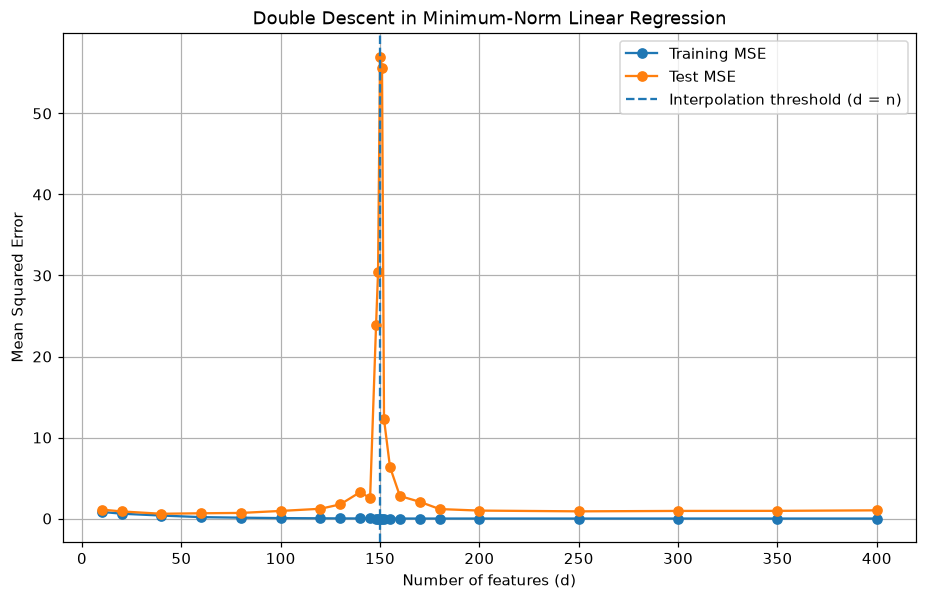

In [9]:
plt.figure(figsize=(10, 6))

plt.plot(
    D_VALUES,
    train_errors,
    marker="o",
    label="Training MSE"
)

plt.plot(
    D_VALUES,
    test_errors,
    marker="o",
    label="Test MSE"
)

plt.axvline(
    x=N_TRAIN,
    linestyle="--",
    label="Interpolation threshold (d = n)"
)

plt.xlabel("Number of features (d)")
plt.ylabel("Mean Squared Error")
plt.title("Double Descent in Minimum-Norm Linear Regression")

plt.legend()
plt.grid(True)

save_and_show("synthetic_01")

In [10]:
def fit_ridge_regression(X, y, alpha):
    """
    Fit Ridge Regression from scratch.

    Parameters
    ----------
    X : array of shape (n_samples, n_features)
    y : array of shape (n_samples,)
    alpha : regularization strength

    Returns
    -------
    w : estimated coefficient vector
    """

    d = X.shape[1]

    # X^T X + alpha I
    regularized_matrix = (
        X.T @ X
        + alpha * np.eye(d)
    )

    # X^T y
    right_hand_side = X.T @ y

    # Solve the linear system
    w = np.linalg.solve(
        regularized_matrix,
        right_hand_side
    )

    return w

def run_synthetic_experiment(seed, ridge_alphas=(0.01, 0.1, 1.0, 10.0)):
    """
    Run one complete synthetic double-descent experiment.
    Returns paired least-squares and ridge errors on identical data.
    """

    local_rng = np.random.default_rng(seed)

    # Generate features
    X_train = local_rng.normal(
        size=(N_TRAIN, D_MAX)
    )

    X_test = local_rng.normal(
        size=(N_TEST, D_MAX)
    )

    # Generate true coefficients
    feature_index = np.arange(D_MAX)

    signs = local_rng.choice(
        [-1.0, 1.0],
        size=D_MAX
    )

    beta = signs * np.exp(
        -0.02 * feature_index
    )

    beta = beta / np.linalg.norm(beta)

    # Generate noisy labels
    y_train_local = (
        X_train @ beta
        + local_rng.normal(
            scale=NOISE_STD,
            size=N_TRAIN
        )
    )

    y_test_local = (
        X_test @ beta
        + local_rng.normal(
            scale=NOISE_STD,
            size=N_TEST
        )
    )

    train_errors_local = []
    test_errors_local = []

    ridge_train = {alpha: [] for alpha in ridge_alphas}
    ridge_test = {alpha: [] for alpha in ridge_alphas}

    for d in D_VALUES:

        Xtr = X_train[:, :d]
        Xte = X_test[:, :d]

        w_hat = fit_min_norm_least_squares(
            Xtr,
            y_train_local
        )

        train_pred = Xtr @ w_hat
        test_pred = Xte @ w_hat

        train_errors_local.append(
            mean_squared_error(
                y_train_local,
                train_pred
            )
        )

        test_errors_local.append(
            mean_squared_error(
                y_test_local,
                test_pred
            )
        )

        for alpha in ridge_alphas:
            w_ridge = fit_ridge_regression(Xtr, y_train_local, alpha)
            ridge_train[alpha].append(mean_squared_error(y_train_local, Xtr @ w_ridge))
            ridge_test[alpha].append(mean_squared_error(y_test_local, Xte @ w_ridge))

    return (
        np.array(train_errors_local),
        np.array(test_errors_local),
        {a: np.array(v) for a, v in ridge_train.items()},
        {a: np.array(v) for a, v in ridge_test.items()}
    )

In [11]:
N_REPETITIONS = 30

all_train_errors = []
all_test_errors = []
RIDGE_ALPHAS = [0.01, 0.1, 1.0, 10.0]
all_ridge_train = {a: [] for a in RIDGE_ALPHAS}
all_ridge_test = {a: [] for a in RIDGE_ALPHAS}

for seed in range(N_REPETITIONS):

    train_err, test_err, ridge_train, ridge_test = run_synthetic_experiment(seed, RIDGE_ALPHAS)

    all_train_errors.append(train_err)
    all_test_errors.append(test_err)
    for a in RIDGE_ALPHAS:
        all_ridge_train[a].append(ridge_train[a])
        all_ridge_test[a].append(ridge_test[a])

all_train_errors = np.array(all_train_errors)
all_test_errors = np.array(all_test_errors)

mean_train_errors = all_train_errors.mean(axis=0)
mean_test_errors = all_test_errors.mean(axis=0)

std_train_errors = all_train_errors.std(axis=0)
std_test_errors = all_test_errors.std(axis=0)

print("Shape train errors:", all_train_errors.shape)
print("Shape test errors:", all_test_errors.shape)
print("Experiment repeated", N_REPETITIONS, "times.")
all_ridge_train = {a: np.array(v) for a, v in all_ridge_train.items()}
all_ridge_test = {a: np.array(v) for a, v in all_ridge_test.items()}
mean_ridge_train = {a: v.mean(axis=0) for a, v in all_ridge_train.items()}
mean_ridge_test = {a: v.mean(axis=0) for a, v in all_ridge_test.items()}
assert all(v.shape == all_test_errors.shape for v in all_ridge_test.values())
print("Paired ridge and least-squares seeds:", list(range(N_REPETITIONS)))


Shape train errors: (30, 24)
Shape test errors: (30, 24)
Experiment repeated 30 times.
Paired ridge and least-squares seeds: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29]


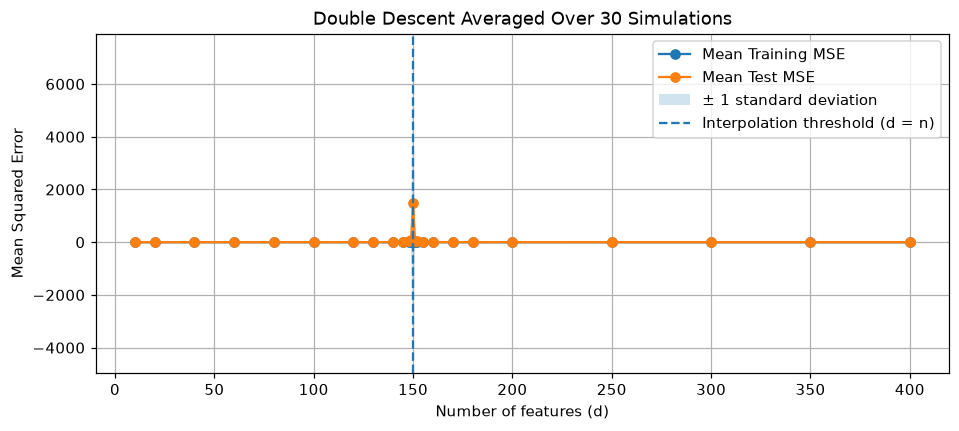

In [12]:
plt.figure(figsize=(10, 4))

# Mean training error
plt.plot(
    D_VALUES,
    mean_train_errors,
    marker="o",
    label="Mean Training MSE"
)

# Mean test error
plt.plot(
    D_VALUES,
    mean_test_errors,
    marker="o",
    label="Mean Test MSE"
)

# Variability across repetitions
plt.fill_between(
    D_VALUES,
    mean_test_errors - std_test_errors,
    mean_test_errors + std_test_errors,
    alpha=0.2,
    label="± 1 standard deviation"
)

# Interpolation threshold
plt.axvline(
    x=N_TRAIN,
    linestyle="--",
    label="Interpolation threshold (d = n)"
)

plt.xlabel("Number of features (d)")
plt.ylabel("Mean Squared Error")
plt.title(
    f"Double Descent Averaged Over {N_REPETITIONS} Simulations"
)

plt.legend()
plt.grid(True)

save_and_show("synthetic_02")

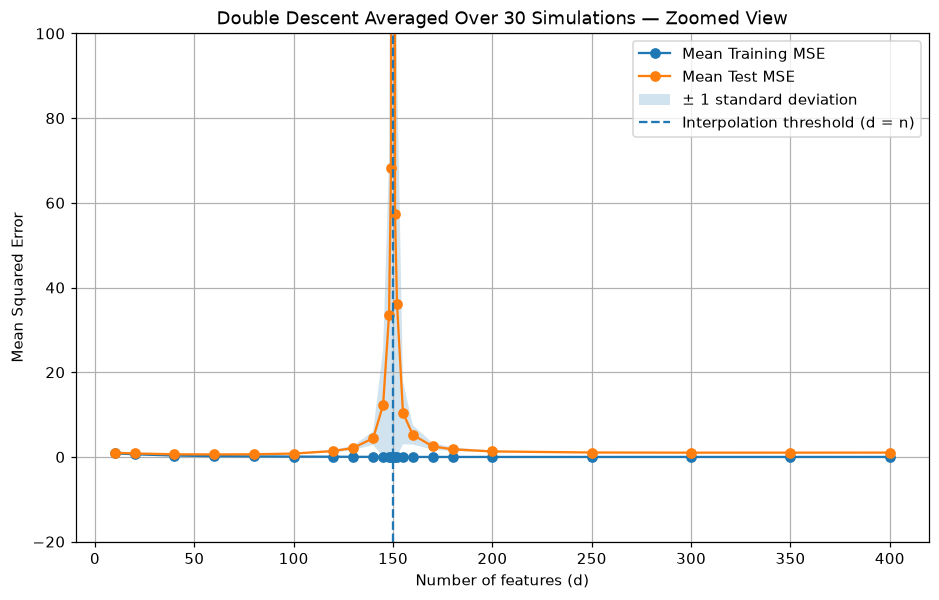

In [13]:
plt.figure(figsize=(10, 6))

# Mean training error
plt.plot(
    D_VALUES,
    mean_train_errors,
    marker="o",
    label="Mean Training MSE"
)

# Mean test error
plt.plot(
    D_VALUES,
    mean_test_errors,
    marker="o",
    label="Mean Test MSE"
)

# Standard deviation band
lower_bound = np.maximum(
    mean_test_errors - std_test_errors,
    0
)

upper_bound = mean_test_errors + std_test_errors

plt.fill_between(
    D_VALUES,
    lower_bound,
    upper_bound,
    alpha=0.2,
    label="± 1 standard deviation"
)

# Interpolation threshold
plt.axvline(
    x=N_TRAIN,
    linestyle="--",
    label="Interpolation threshold (d = n)"
)

plt.xlabel("Number of features (d)")
plt.ylabel("Mean Squared Error")
plt.title(
    f"Double Descent Averaged Over {N_REPETITIONS} Simulations — Zoomed View"
)

# Zoom on the informative part of the curve
plt.ylim(-20, 100)

plt.legend()
plt.grid(True)

save_and_show("synthetic_03")

In [14]:
# Ridge is defined before the paired repeated experiment.


In [15]:
RIDGE_ALPHA = 1.0
ridge_train_errors = mean_ridge_train[RIDGE_ALPHA]
ridge_test_errors = mean_ridge_test[RIDGE_ALPHA]
print("Ridge comparison uses the same 30 datasets as least squares.")


Ridge comparison uses the same 30 datasets as least squares.


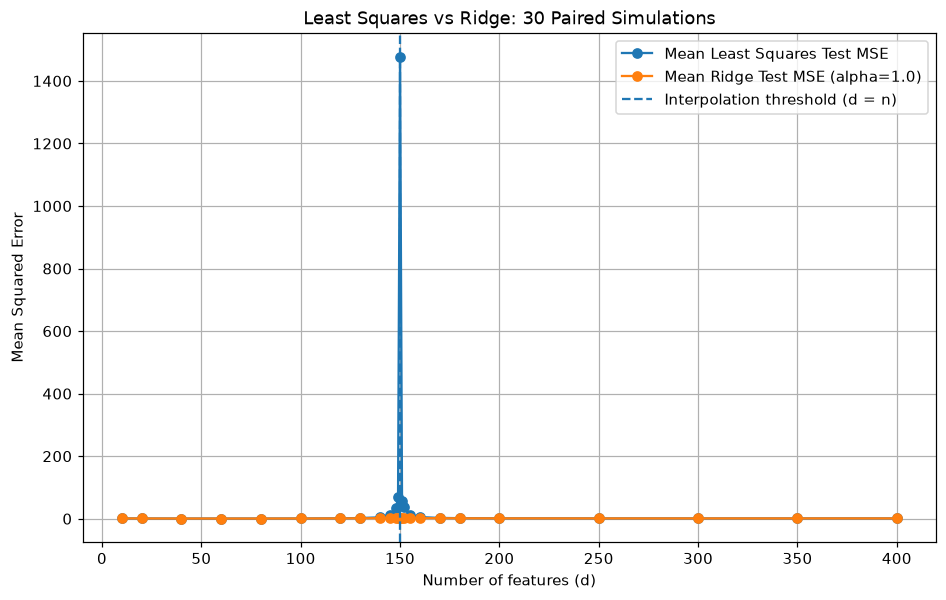

In [16]:
plt.figure(figsize=(10, 6))

# Least Squares
plt.plot(
    D_VALUES,
    mean_test_errors,
    marker="o",
    label="Mean Least Squares Test MSE"
)

# Ridge
plt.plot(
    D_VALUES,
    ridge_test_errors,
    marker="o",
    label=f"Mean Ridge Test MSE (alpha={RIDGE_ALPHA})"
)

# Interpolation threshold
plt.axvline(
    x=N_TRAIN,
    linestyle="--",
    label="Interpolation threshold (d = n)"
)

plt.xlabel("Number of features (d)")
plt.ylabel("Mean Squared Error")
plt.title(f"Least Squares vs Ridge: {N_REPETITIONS} Paired Simulations")

plt.legend()
plt.grid(True)

save_and_show("synthetic_04")

In [17]:
# Each alpha uses identical features, coefficients and noise within each seed.
# This is a sensitivity analysis; alpha is not selected using test performance.
ridge_results = mean_ridge_test
print("Ridge sensitivity analysis averaged over", N_REPETITIONS, "paired runs.")


Ridge sensitivity analysis averaged over 30 paired runs.


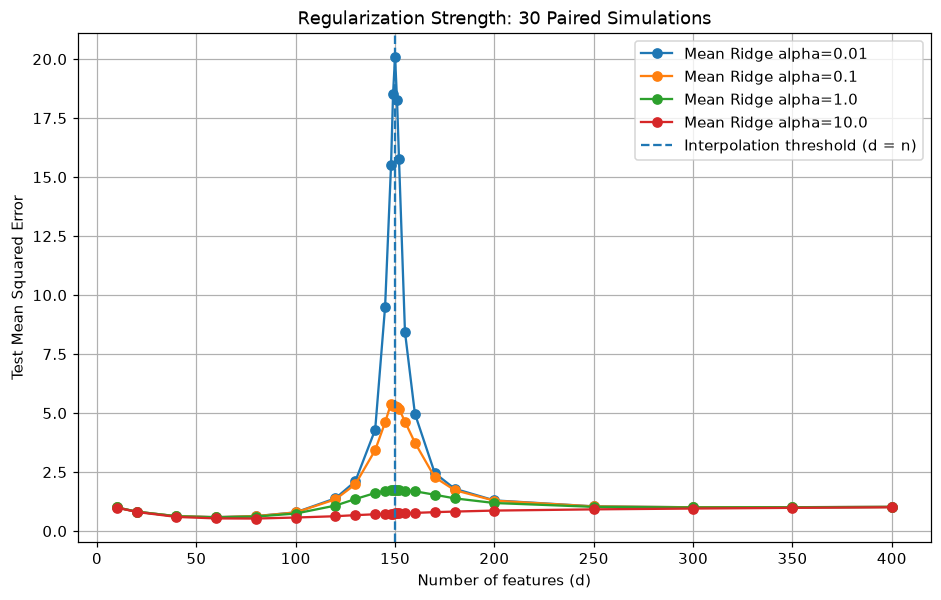

In [18]:
plt.figure(figsize=(10, 6))

for alpha in RIDGE_ALPHAS:
    plt.plot(
        D_VALUES,
        ridge_results[alpha],
        marker="o",
        label=f"Mean Ridge alpha={alpha}"
    )

plt.axvline(
    x=N_TRAIN,
    linestyle="--",
    label="Interpolation threshold (d = n)"
)

plt.xlabel("Number of features (d)")
plt.ylabel("Test Mean Squared Error")
plt.title(f"Regularization Strength: {N_REPETITIONS} Paired Simulations")

plt.legend()
plt.grid(True)

save_and_show("synthetic_05")

## Paired comparison on a logarithmic scale

Each least-squares and ridge curve uses identical data within each of 30 seeds. The bands below are the 25th–75th percentiles of test errors, not confidence intervals. Positive test errors are plotted directly on a logarithmic axis; training errors near zero remain in the existing linear-scale figures.


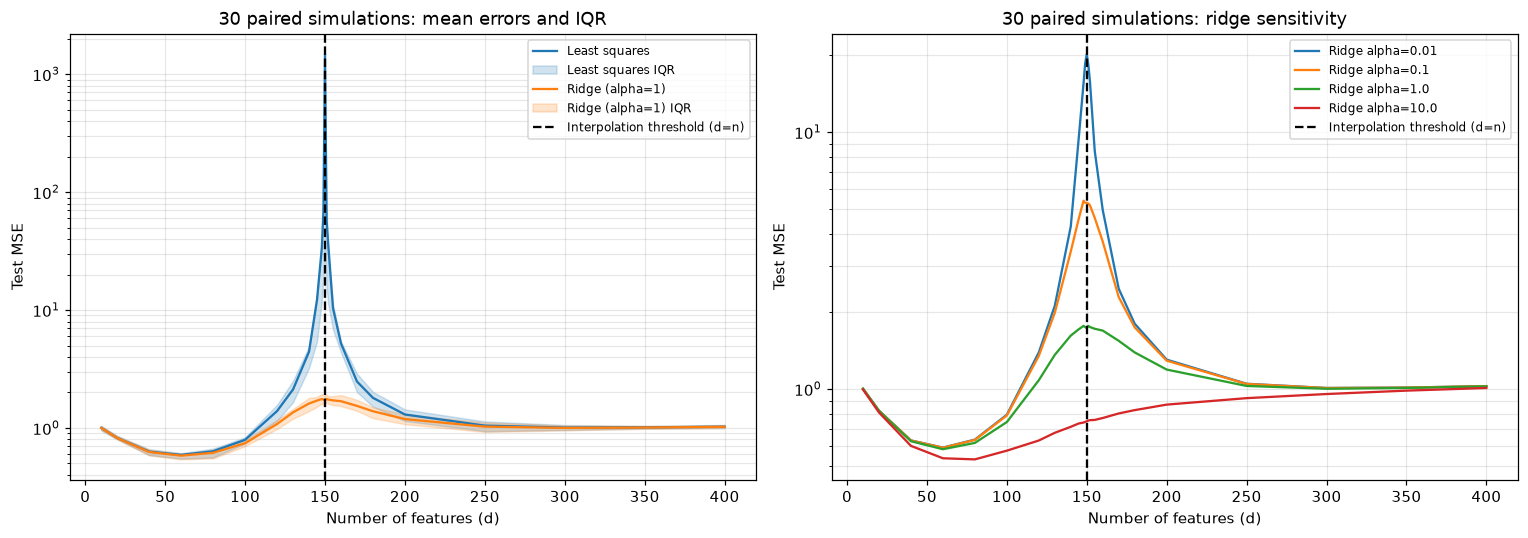

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for values, label, color in [(all_test_errors, "Least squares", "C0"),
                             (all_ridge_test[RIDGE_ALPHA], "Ridge (alpha=1)", "C1")]:
    axes[0].plot(D_VALUES, values.mean(axis=0), label=label, color=color)
    lo, hi = np.percentile(values, [25, 75], axis=0)
    axes[0].fill_between(D_VALUES, lo, hi, alpha=0.2, color=color, label=f"{label} IQR")
axes[0].set_title("30 paired simulations: mean errors and IQR")
for alpha in RIDGE_ALPHAS:
    axes[1].plot(D_VALUES, mean_ridge_test[alpha], label=f"Ridge alpha={alpha}")
axes[1].set_title("30 paired simulations: ridge sensitivity")
for ax in axes:
    ax.axvline(N_TRAIN, color="black", linestyle="--", label="Interpolation threshold (d=n)")
    ax.set_yscale("log")
    ax.set_xlabel("Number of features (d)")
    ax.set_ylabel("Test MSE")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend(fontsize=8)
fig.tight_layout()
save_and_show("synthetic_06")


In [20]:
peak = int(np.argmax(mean_test_errors))
pre = np.flatnonzero(D_VALUES < N_TRAIN)
best_pre = pre[np.argmin(mean_test_errors[pre])]
print("Mean LS peak d / MSE:", D_VALUES[peak], mean_test_errors[peak])
print("Lowest pre-interpolation mean LS MSE:", mean_test_errors[best_pre], "at d =", D_VALUES[best_pre])
print("Final mean LS / ridge(alpha=1):", mean_test_errors[-1], mean_ridge_test[1.0][-1])
print("At threshold mean LS / ridge(alpha=1):", mean_test_errors[peak], mean_ridge_test[1.0][peak])


Mean LS peak d / MSE: 150 1477.947374053672
Lowest pre-interpolation mean LS MSE: 0.5911669077638135 at d = 60
Final mean LS / ridge(alpha=1): 1.0255893061155905 1.0236233828786057
At threshold mean LS / ridge(alpha=1): 1477.947374053672 1.7250150806873508


## Interpretation of the synthetic results

The 30-run mean least-squares curve shows double descent: error initially falls, rises sharply at the verified interpolation threshold d = n = 150, and falls again beyond it. The mean peak MSE is about 1,477.95. At d = 400 it is 1.026, which remains above the best pre-interpolation mean MSE of 0.591 at d = 60. Thus, the second descent does not imply that the largest model is the best model in this experiment.

On the same datasets, ridge with alpha = 1 reduces the mean error at d = 150 to about 1.725. At d = 400, its mean error is 1.024, very close to least squares. The main benefit of this regularization strength is suppression of the interpolation spike. The sensitivity curves are descriptive; no alpha has been selected using these test results. The IQR and mean summarize different aspects of the distribution, so the mean need not lie inside the middle-50% band, especially near interpolation.
